# 04 · Anomalies : autoencodeur vs Isolation Forest

**Date :** 4 novembre 2026

**Ce qui est fait :**
1. Autoencodeur PyTorch : 3 tailles de goulot, entraînées sur le trafic **normal** de train uniquement.
2. Isolation Forest : 2 tailles d'échantillon, entraînées sur les mêmes flux.
3. Seuil d'alerte de chaque modèle : **99e percentile du score sur le benign de val**.
4. Choix des réglages et du modèle retenu **sur val** : rappel moyen par classe d'attaque, sans heartbleed (2 flux).
5. Mesure sur test_connu et test_inconnu, réglages et seuils figés.

**Pourquoi :** le RF et le MLP ne reconnaissent que ce qu'ils ont appris : ils ratent presque tout le portscan et tout le bot (notebook 03). Un détecteur d'anomalies n'a pas besoin d'exemples d'attaques : il signale ce qui ne ressemble pas au trafic normal. C'est la deuxième comparaison demandée (autoencodeur vs Isolation Forest).

**Protocole fixé avant tout calcul.** Rien n'est réglé sur test_connu ni sur test_inconnu (règle 7). Le critère de choix utilise uniquement des attaques connues (celles de val) : rien ne garantit donc que le modèle retenu soit aussi le meilleur sur les attaques inconnues.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, str(Path.cwd().parent / "src"))
from isocrates.ml.data import LABEL, BENIGN, ROOT
from isocrates.ml.supervised import load_sets, signed_log, save_model, MODELS
from isocrates.ml.anomaly import (fit_autoencoder, reconstruction_error, fit_isolation_forest, isolation_score,
                                  threshold_from_benign, detection_table, mean_attack_recall)

REPORTS = ROOT / "reports"
sns.set_theme(style="whitegrid")

sets, features = load_sets()

X_train = sets["train"][features].to_numpy(np.float32)
X_val = sets["val"][features].to_numpy(np.float32)
X_connu = sets["test_connu"][features].to_numpy(np.float32)
X_inconnu = sets["test_inconnu"][features].to_numpy(np.float32)
y_train = sets["train"][LABEL].to_numpy()
y_val = sets["val"][LABEL].to_numpy()
y_connu = sets["test_connu"][LABEL].to_numpy()
y_inconnu = sets["test_inconnu"][LABEL].to_numpy()
del sets   # libère la mémoire : seuls les tableaux numpy servent ici

# Le détecteur n'apprend que le trafic normal
X_train_benign = X_train[y_train == BENIGN]
X_val_benign = X_val[y_val == BENIGN]
print("Flux normaux pour l'entraînement :", len(X_train_benign), "· benign de val :", len(X_val_benign))

Flux normaux pour l'entraînement : 699151 · benign de val : 149818


## 1. Autoencodeur (PyTorch)

Entrées : `sign(x)·log(1+|x|)` puis standardisation, **ajustés sur le benign de train**.

Réseau : 78 → 64 → goulot → 64 → 78. Il apprend à recopier le trafic normal en passant par le goulot. Le **score d'anomalie** d'un flux est son erreur de reconstruction.

Pour chaque taille de goulot : 20 époques, en gardant celle dont l'erreur sur le benign de val est la plus basse. Puis seuil et rappel moyen sur val.

In [2]:
scaler = StandardScaler()
scaler.fit(signed_log(X_train_benign))      # moyenne et écart-type du trafic normal de train

Z_train_benign = scaler.transform(signed_log(X_train_benign))
Z_val_benign = scaler.transform(signed_log(X_val_benign))
Z_val = scaler.transform(signed_log(X_val))
Z_connu = scaler.transform(signed_log(X_connu))
Z_inconnu = scaler.transform(signed_log(X_inconnu))

ae_results = []
ae_models = []
ae_histories = {}

for latent in [8, 16, 32]:
    model, history, best_epoch, duration = fit_autoencoder(Z_train_benign, Z_val_benign, latent_size=latent)
    scores = reconstruction_error(model, Z_val)
    threshold = threshold_from_benign(scores, y_val)
    table = detection_table(y_val, scores, threshold)

    ae_histories["goulot " + str(latent)] = history
    ae_models.append(model)
    ae_results.append({
        "goulot": latent,
        "meilleure époque": best_epoch,
        "perte val": round(history["perte val"].min(), 4),
        "seuil": round(float(threshold), 4),
        "rappel moyen val": round(mean_attack_recall(table), 4),
        "temps (s)": round(duration),
    })

ae_table = pd.DataFrame(ae_results)
best = ae_table["rappel moyen val"].idxmax()
autoencoder = ae_models[best]
latent_size = int(ae_table.loc[best, "goulot"])
print("Autoencodeur retenu : goulot", latent_size)
ae_table

Autoencodeur retenu : goulot 8


,goulot,meilleure époque,perte val,seuil,rappel moyen val,temps (s)
0,8,20,0.0206,0.1820,0.8739,67
1,16,20,0.0071,0.0677,0.6769,69
2,32,20,0.0020,0.0239,0.8355,71


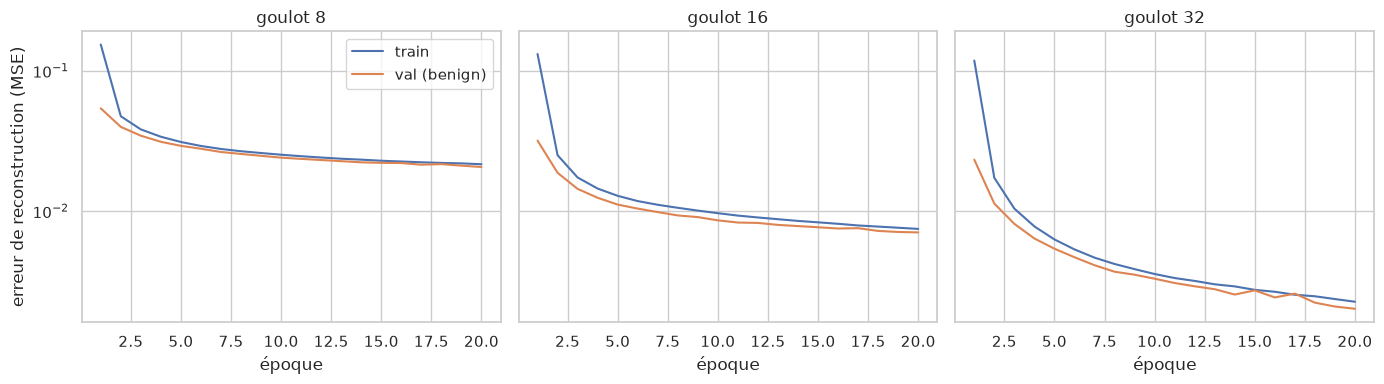

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (name, history) in zip(axes, ae_histories.items()):
    ax.plot(history["époque"], history["perte train"], label="train")
    ax.plot(history["époque"], history["perte val"], label="val (benign)")
    ax.set_title(name)
    ax.set_xlabel("époque")
    ax.set_yscale("log")
axes[0].set_ylabel("erreur de reconstruction (MSE)")
axes[0].legend()
fig.tight_layout()
fig.savefig(REPORTS / "04_ae_courbes.png", dpi=150)
plt.show()

## 2. Isolation Forest

La forêt isole chaque flux par des coupures au hasard : un flux anormal s'isole en peu de coupures. Les arbres ne dépendent pas de l'échelle des valeurs, donc on garde les données brutes. On essaie 2 tailles d'échantillon par arbre.

In [4]:
if_results = []
if_models = []

for max_samples in [256, 4096]:
    forest, duration = fit_isolation_forest(X_train_benign, max_samples)
    scores = isolation_score(forest, X_val)
    threshold = threshold_from_benign(scores, y_val)
    table = detection_table(y_val, scores, threshold)

    if_models.append(forest)
    if_results.append({
        "max_samples": max_samples,
        "seuil": round(float(threshold), 4),
        "rappel moyen val": round(mean_attack_recall(table), 4),
        "temps (s)": round(duration),
    })

if_table = pd.DataFrame(if_results)
best = if_table["rappel moyen val"].idxmax()
forest = if_models[best]
print("Isolation Forest retenue : max_samples", if_table.loc[best, "max_samples"])
if_table

Isolation Forest retenue : max_samples 4096


,max_samples,seuil,rappel moyen val,temps (s)
0,256,0.6097,0.0380,0
1,4096,0.4969,0.2548,1


## 3. Comparaison sur val et choix du modèle

Les seuils sont figés ici. Le modèle retenu pour le pipeline est celui qui a le meilleur rappel moyen sur val.

In [5]:
# Scores et seuils définitifs des deux modèles retenus
ae_val = reconstruction_error(autoencoder, Z_val)
if_val = isolation_score(forest, X_val)
ae_threshold = threshold_from_benign(ae_val, y_val)
if_threshold = threshold_from_benign(if_val, y_val)

ae_val_table = detection_table(y_val, ae_val, ae_threshold)
if_val_table = detection_table(y_val, if_val, if_threshold)

ae_recall = mean_attack_recall(ae_val_table)
if_recall = mean_attack_recall(if_val_table)
print("Rappel moyen sur val, sans heartbleed : autoencodeur =", round(ae_recall, 4), "· Isolation Forest =", round(if_recall, 4))

if ae_recall >= if_recall:
    retained = "autoencodeur"
else:
    retained = "isolation_forest"
print("Modèle retenu pour le pipeline :", retained)

pd.concat({"Autoencodeur": ae_val_table, "Isolation Forest": if_val_table}, axis=1).round(3)

Rappel moyen sur val, sans heartbleed : autoencodeur = 0.8739 · Isolation Forest = 0.2548
Modèle retenu pour le pipeline : autoencodeur


Autoencodeur                              Isolation Forest  \
                         flux alertes part détectée    AUC             flux   
classe                                                                        
benign                 149818    1499         0.010    NaN           149818   
dos_goldeneye            1015     429         0.423  0.989             1015   
dos_hulk                23848   23848         1.000  0.996            23848   
dos_slowhttptest          730     599         0.821  0.995              730   
dos_slowloris             851     851         1.000  1.000              851   
ftp_patator               600     600         1.000  0.997              600   
heartbleed                  2       2         1.000  1.000                2   
ssh_patator               444     444         1.000  0.996              444   

                                               
                 alertes part détectée    AUC  
classe                                         
benign              1499         0.010    NaN  
dos_goldeneye        169         0.167  0.937  
dos_hulk            4033         0.169  0.978  
dos_slowhttptest     460         0.630  0.952  
dos_slowloris        479         0.563  0.935  
ftp_patator            0         0.000  0.710  
heartbleed             2         1.000  1.000  
ssh_patator            0         0.000  0.839

## 4. Mesure sur test_connu

Modèles et seuils figés. Heartbleed (2 flux) reste affiché, mais il est exclu du rappel moyen.

In [6]:
ae_connu_table = detection_table(y_connu, reconstruction_error(autoencoder, Z_connu), ae_threshold)
if_connu_table = detection_table(y_connu, isolation_score(forest, X_connu), if_threshold)

print("Rappel moyen sur test_connu, sans heartbleed : autoencodeur =", round(mean_attack_recall(ae_connu_table), 4),
      "· Isolation Forest =", round(mean_attack_recall(if_connu_table), 4))
pd.concat({"Autoencodeur": ae_connu_table, "Isolation Forest": if_connu_table}, axis=1).round(3)

Rappel moyen sur test_connu, sans heartbleed : autoencodeur = 0.9497 · Isolation Forest = 0.2681


Autoencodeur                              Isolation Forest  \
                         flux alertes part détectée    AUC             flux   
classe                                                                        
benign                 149820    1482         0.010    NaN           149820   
dos_goldeneye            1015     856         0.843  0.992             1015   
dos_hulk                23849   23849         1.000  0.996            23849   
dos_slowhttptest          730     729         0.999  0.998              730   
dos_slowloris             852     747         0.877  0.997              852   
ftp_patator               601     601         1.000  0.997              601   
heartbleed                  2       2         1.000  0.998                2   
ssh_patator               444     435         0.980  0.996              444   

                                               
                 alertes part détectée    AUC  
classe                                         
benign              1608         0.011    NaN  
dos_goldeneye        230         0.227  0.940  
dos_hulk            3961         0.166  0.977  
dos_slowhttptest     677         0.927  0.981  
dos_slowloris        246         0.289  0.933  
ftp_patator            0         0.000  0.698  
heartbleed             2         1.000  1.000  
ssh_patator            0         0.000  0.826

## 5. Mesure sur test_inconnu : le vrai objectif

Ces attaques n'ont jamais été vues. On regarde surtout **portscan**, **bot** et les attaques web, que le RF ne détecte pas ou presque. Sql_injection n'a que 12 flux : son chiffre est peu fiable.

In [7]:
ae_inconnu = reconstruction_error(autoencoder, Z_inconnu)
if_inconnu = isolation_score(forest, X_inconnu)

ae_inconnu_table = detection_table(y_inconnu, ae_inconnu, ae_threshold)
if_inconnu_table = detection_table(y_inconnu, if_inconnu, if_threshold)

print("Rappel moyen sur test_inconnu : autoencodeur =", round(mean_attack_recall(ae_inconnu_table), 4),
      "· Isolation Forest =", round(mean_attack_recall(if_inconnu_table), 4))
pd.concat({"Autoencodeur": ae_inconnu_table, "Isolation Forest": if_inconnu_table}, axis=1).round(3)

Rappel moyen sur test_inconnu : autoencodeur = 0.4693 · Isolation Forest = 0.09


Autoencodeur                               \
                                flux alertes part détectée    AUC   
classe                                                              
benign                        396886    6065         0.015    NaN   
bot                              735     540         0.735  0.987   
ddos                           95683   95683         1.000  0.997   
portscan                      160106  160099         1.000  0.999   
webattack_bruteforce            1360      73         0.054  0.946   
webattack_sql_injection           12       0         0.000  0.940   
webattack_xss                    661      18         0.027  0.945   

                        Isolation Forest                               
                                    flux alertes part détectée    AUC  
classe                                                                 
benign                            396886    4734         0.012    NaN  
bot                                  735      44         0.060  0.649  
ddos                               95683   37861         0.396  0.981  
portscan                          160106     770         0.005  0.972  
webattack_bruteforce                1360      71         0.052  0.696  
webattack_sql_injection               12       0         0.000  0.735  
webattack_xss                        661      18         0.027  0.686

In [8]:
# Fausses alertes et précision : parmi les alertes, quelle part est une vraie attaque ?
rows = []
for name, table in [("Autoencodeur", ae_inconnu_table), ("Isolation Forest", if_inconnu_table)]:
    false_alerts = table.loc[BENIGN, "alertes"]
    all_alerts = table["alertes"].sum()
    rows.append({
        "modèle": name,
        "alertes": all_alerts,
        "fausses alertes": false_alerts,
        "taux de fausses alertes (benign)": round(table.loc[BENIGN, "part détectée"], 4),
        "précision des alertes": round((all_alerts - false_alerts) / all_alerts, 4),
    })
pd.DataFrame(rows).set_index("modèle")

,alertes,fausses alertes,taux de fausses alertes (benign),précision des alertes
modèle,,,,
Autoencodeur,262478,6065,0.0153,0.9769
Isolation Forest,43498,4734,0.0119,0.8912


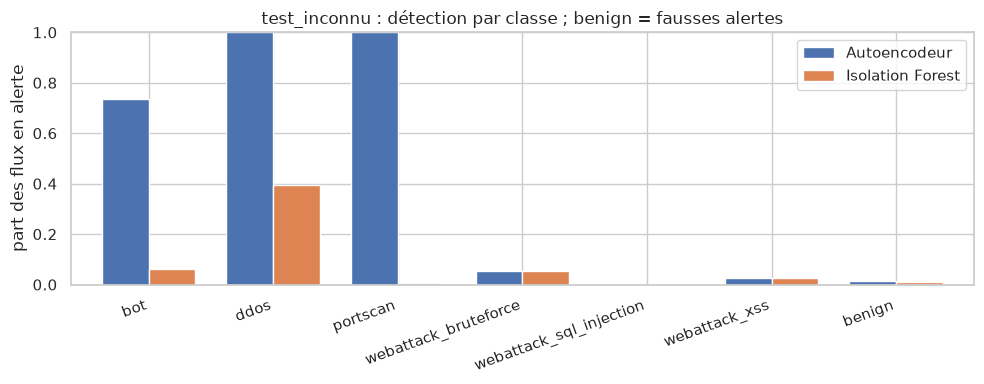

In [9]:
names = [name for name in ae_inconnu_table.index if name != BENIGN] + [BENIGN]
detection = pd.DataFrame({
    "Autoencodeur": ae_inconnu_table.loc[names, "part détectée"],
    "Isolation Forest": if_inconnu_table.loc[names, "part détectée"],
})

fig, ax = plt.subplots(figsize=(10, 4))
detection.plot.bar(ax=ax, width=0.75, color=["#4C72B0", "#DD8452"])
ax.set_ylabel("part des flux en alerte")
ax.set_ylim(0, 1)
ax.set_xlabel("")
ax.set_title("test_inconnu : détection par classe ; benign = fausses alertes")
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
fig.tight_layout()
fig.savefig(REPORTS / "04_detection_test_inconnu.png", dpi=150)
plt.show()

## 6. Scores par classe

Pour le graphique seulement : au plus 5 000 flux par classe de test_inconnu (graine fixe). La ligne verticale est le seuil : à sa droite, le flux déclenche une alerte.

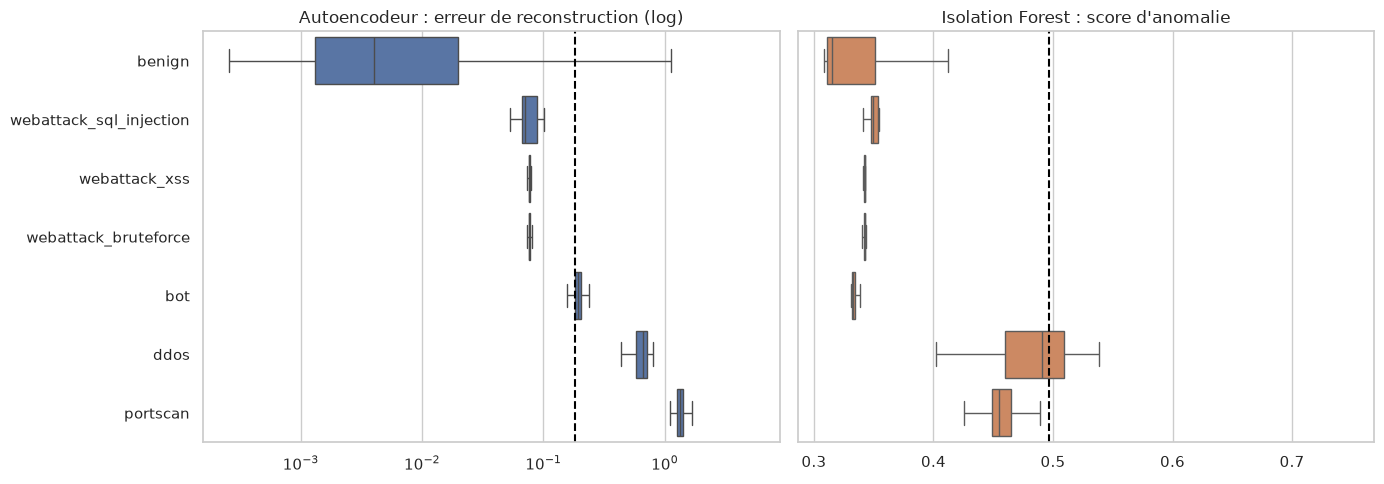

In [10]:
rng = np.random.default_rng(0)
sample_index = []
for name in np.unique(y_inconnu):
    positions = np.flatnonzero(y_inconnu == name)
    n = min(len(positions), 5000)
    sample_index.extend(rng.choice(positions, size=n, replace=False))
sample_index = np.array(sample_index)

plot_data = pd.DataFrame({
    "classe": y_inconnu[sample_index],
    "autoencodeur": ae_inconnu[sample_index],
    "isolation": if_inconnu[sample_index],
})
order = plot_data.groupby("classe")["autoencodeur"].median().sort_values().index

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
sns.boxplot(data=plot_data, y="classe", x="autoencodeur", order=order, fliersize=0, log_scale=True, color="#4C72B0", ax=axes[0])
axes[0].axvline(ae_threshold, color="black", linestyle="--")
axes[0].set_title("Autoencodeur : erreur de reconstruction (log)")
sns.boxplot(data=plot_data, y="classe", x="isolation", order=order, fliersize=0, color="#DD8452", ax=axes[1])
axes[1].axvline(if_threshold, color="black", linestyle="--")
axes[1].set_title("Isolation Forest : score d'anomalie")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.tight_layout()
fig.savefig(REPORTS / "04_scores_par_classe.png", dpi=150)
plt.show()

## 7. Sauvegarde

Dans `models/` (exclu de Git) : les deux détecteurs, leurs seuils et le nom du modèle retenu, pour le notebook 05.

In [11]:
torch.save(autoencoder.state_dict(), MODELS / "autoencoder.pt")
save_model({"scaler": scaler, "latent_size": latent_size, "threshold": ae_threshold, "features": features}, "autoencoder_meta")
save_model({"forest": forest, "threshold": if_threshold, "features": features}, "isolation_forest")
save_model({"retained": retained}, "anomaly_choice")

for path in sorted(MODELS.glob("*")):
    print(path.name, ":", round(path.stat().st_size / 1e6, 2), "Mo")

anomaly_choice.joblib : 0.0 Mo
autoencoder.pt : 0.05 Mo
autoencoder_meta.joblib : 0.0 Mo
isolation_forest.joblib : 0.82 Mo
mlp.joblib : 0.29 Mo
rf.joblib : 1.22 Mo


## Observations

1. **L'autoencodeur est retenu sur val** (goulot 8) : rappel moyen de **0,874**, contre **0,255** pour l'Isolation Forest (`max_samples` = 4096). Ce choix se confirme sur les deux tests (test_connu 0,950 contre 0,268 ; test_inconnu 0,469 contre 0,090), mais ces mesures n'ont servi à aucun choix.
2. **Il attrape une grande partie de ce que le RF rate, sur test_inconnu.** Portscan : 160 099 flux sur 160 106. DDoS : 95 683 sur 95 683. Bot : 540 sur 735 (73,5 %). Pour le RF, ces chiffres étaient de 55 flux de portscan, 97,7 % de DDoS et 0 bot.
3. **Il rate presque toutes les attaques web.** Bruteforce 5,4 % (73 sur 1 360), XSS 2,7 % (18 sur 661), sql_injection 0 sur 12. Leur AUC reste pourtant élevée (environ 0,94) : leurs scores sont au-dessus du benign typique, mais sous le seuil. Baisser le seuil les attraperait, au prix de nombreuses fausses alertes.
4. **Les trois modèles se complètent.** Sur les attaques web, le MLP du notebook 03 détecte 94,3 % du bruteforce et 99,7 % du XSS, alors que le RF en détecte environ 11 % et l'autoencodeur moins de 6 %. L'association RF + autoencodeur prévue dans l'architecture laissera donc passer la plupart des attaques web. On ne doit pas choisir le MLP à partir de ces chiffres de test (règle 7), mais il faut en parler : décision à prendre avant le notebook 05.
5. **Bot est fragile.** Ses scores forment un paquet très serré juste autour du seuil (voir le graphique) : une petite variation du seuil changerait beaucoup les 73,5 %.
6. **Fausses alertes.** Le seuil est réglé pour 1 % sur le benign de val. On mesure 0,99 % sur test_connu, mais **1,53 %** sur test_inconnu (6 065 flux) : le trafic normal des autres jours s'éloigne un peu de celui appris. Le regroupement en incidents (notebook 05) devra réduire cette charge pour l'analyste.
7. **La précision des alertes (97,7 %) est flatteuse.** Elle est élevée parce que portscan et DDoS représentent 39 % des flux de test_inconnu. Avec moins d'attaques, comme dans un vrai réseau, elle serait bien plus basse.
8. **Le choix du goulot n'est pas très stable.** Le rappel moyen sur val n'évolue pas de façon régulière : 0,874 (goulot 8), 0,677 (16), 0,836 (32). Le goulot 8 a pourtant la plus grande erreur de reconstruction. L'écart vient surtout de quelques classes, comme dos_goldeneye (42 % sur val, 84 % sur test_connu). Un seul entraînement (une seule graine) ne permet pas de séparer l'effet du goulot du hasard.
9. **L'entraînement n'a pas atteint de plateau.** Les 3 réseaux ont leur meilleure erreur à la dernière époque (20). Plus d'époques réduiraient encore l'erreur, sans garantie d'une meilleure détection.
10. **L'Isolation Forest sépare moins bien.** Son AUC va de 0,65 (bot) à 0,98 (DDoS). Elle ne signale presque aucun portscan (0,5 %), car leurs scores restent juste sous le seuil, et aucun flux ftp ou ssh_patator (AUC d'environ 0,7 et 0,83 sur val et test_connu). Avantage : elle s'entraîne en 1 seconde, contre environ 1 minute.
11. **Détecter n'est pas nommer.** Le détecteur dit seulement « anormal » : c'est le label « inconnu » de l'architecture.

**Note du 4 novembre (notebook 04b) :** sur 5 graines, la détection du bot par l'autoencodeur (goulot 8) est de 48,0 % ± 33,6, de 21,6 % à 94,3 %. Le 73,5 % ci-dessus n'est qu'un de ces résultats. Portscan et DDoS restent à environ 100 %.